In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/valakhorasani/divar-real-estate-dataset1m-persian-property-ads/real_estate_ads.csv


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from typing import Dict, Any, Tuple

## 1. Dataset Overview 

In [3]:
df = pd.read_csv('/kaggle/input/datasets/valakhorasani/divar-real-estate-dataset1m-persian-property-ads/real_estate_ads.csv')
df.head()

/tmp/ipykernel_16/3531332855.py:1: DtypeWarning: Columns (10,26,28,52) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('/kaggle/input/datasets/valakhorasani/divar-real-estate-dataset1m-persian-property-ads/real_estate_ads.csv')


,cat2_slug,cat3_slug,city_slug,neighborhood_slug,created_at_month,user_type,description,title,rent_mode,rent_value,...,property_type,regular_person_capacity,extra_person_capacity,cost_per_extra_person,rent_price_on_regular_days,rent_price_on_special_days,rent_price_at_weekends,location_latitude,location_longitude,location_radius
0,temporary-rent,villa,karaj,mehrshahr,2024-08-01 00:00:00,مشاور املاک,۵۰۰متر\n۲۰۰متر بنا دوبلکس\n۳خواب\nاستخر آبگرم ...,باغ ویلا اجاره روزانه استخر داخل لشکرآباد سهیلیه,NaN,NaN,...,NaN,4.0,6,350000.0,1500000.0,3.500000e+09,3500000.0,35.811684,50.936600,500.0
1,residential-sell,apartment-sell,tehran,gholhak,2024-05-01 00:00:00,مشاور املاک,دسترسی عالی به مترو و شریعتی \nمشاعات تمیز \nب...,۶۰ متر قلهک فول امکانات,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,500.0
2,residential-rent,apartment-rent,tehran,tohid,2024-10-01 00:00:00,NaN,تخلیه پایان ماه,آپارتمان ۳ خوابه ۱۳۲ متر,مقطوع,26000000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.703865,51.373459,NaN
3,commercial-rent,office-rent,tehran,elahiyeh,2024-06-01 00:00:00,NaN,فرشته تاپ لوکیشن\n۹۰ متر موقعیت اداری\nیک اتاق...,فرشته ۹۰ متر دفتر کار مدرن موقعیت اداری,مقطوع,95000000.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,residential-sell,apartment-sell,mashhad,emamreza,2024-05-01 00:00:00,مشاور املاک,هلدینگ ساختمانی اکبری\n\nهمراه شما هستیم برای ...,۱۱۵ متری/شمالی رو به آفتاب/اکبری,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

df_sale = df[df['cat2_slug'] == 'residential-sell'].copy()
df_apartment_sale = df[df['cat3_slug'] == 'apartment-sell'].copy()

print(f"تعداد کل رکوردها: {len(df)}")
print(f"تعداد آگهی‌های فروش: {len(df_sale)}")
print(f"تعداد آپارتمان‌های فروشی: {len(df_apartment_sale)}")

تعداد کل رکوردها: 1000000
تعداد آگهی‌های فروش: 558708
تعداد آپارتمان‌های فروشی: 303385


## 2. Numerical Features Analysis

In [5]:
import pandas as pd


def analyze_columns(df, show_details=True, top_n=3):
    """
    Comprehensive analysis of each column in a DataFrame.

    Parameters:
    ----------
    df : pd.DataFrame
        Input DataFrame
    show_details : bool
        If True, prints detailed information for each column
    top_n : int
        Number of most frequent values to display for categorical columns

    Returns:
    -------
    pd.DataFrame
        Summary table containing: data type, count and percentage of missing values,
        number of unique values, number of duplicate rows in that column, and key statistics
    """

    summary = []

    for col in df.columns:
        series = df[col]

        # --- Base statistics ---
        dtype = str(series.dtype)
        n_missing = series.isna().sum()
        pct_missing = round(n_missing / len(df) * 100, 2)
        n_unique = series.nunique(dropna=True)

        # Number of rows whose value is duplicated in this column
        # (i.e., how many rows belong to duplicate groups)
        n_dup_rows = series.duplicated(keep=False).sum()
        pct_dup_rows = round(n_dup_rows / len(df) * 100, 2)

        # Most frequent value (if any)
        try:
            top_value = series.mode(dropna=True).iloc[0] if not series.dropna().empty else None
            top_freq = series.value_counts(dropna=True).iloc[0] if not series.dropna().empty else None
        except Exception:
            top_value, top_freq = None, None

        # --- Data-type-specific statistics ---
        extra = ""
        if pd.api.types.is_numeric_dtype(series) and not pd.api.types.is_bool_dtype(series):
            s = series.dropna()
            if not s.empty:
                extra = (f"min={s.min():.2f} | max={s.max():.2f} | "
                         f"mean={s.mean():.2f} | median={s.median():.2f}")
        elif pd.api.types.is_bool_dtype(series):
            s = series.dropna()
            if not s.empty:
                n_true = int(s.sum())
                n_false = int((~s.astype(bool)).sum())
                extra = f"True={n_true} ({n_true/len(s)*100:.1f}%) | False={n_false}"
        else:  # object / category
            top_list = series.value_counts(dropna=True).head(top_n)
            if not top_list.empty:
                extra = " | ".join([f"{idx}: {cnt}" for idx, cnt in top_list.items()])

        summary.append({
            "column": col,
            "dtype": dtype,
            "n_missing": n_missing,
            "pct_missing": pct_missing,
            "n_unique": n_unique,
            "n_dup_rows": n_dup_rows,
            "pct_dup_rows": pct_dup_rows,
            "top_value": top_value,
            "top_freq": top_freq,
            "details": extra,
        })

    summary_df = pd.DataFrame(summary)

    # --- Print column-by-column details ---
    if show_details:
        print("=" * 100)
        print(f"Column-by-Column DataFrame Analysis | Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
        print(f"Total fully duplicate rows (across entire DataFrame): {df.duplicated().sum():,}")
        print("=" * 100)

        for row in summary_df.itertuples():
            print(f"\nColumn: {row.column}  [{row.dtype}]")
            print(f"   • Missing       : {row.n_missing:,} ({row.pct_missing}%)")
            print(f"   • Unique values  : {row.n_unique:,}")
            print(f"   • Duplicate rows in this column: {row.n_dup_rows:,} ({row.pct_dup_rows}%)")
            if row.top_value is not None:
                print(f"   • Most frequent  : {row.top_value}  (count: {row.top_freq:,})")
            if row.details:
                print(f"   • Details        : {row.details}")
        print("\n" + "=" * 100)

    return summary_df

In [6]:
analyze_columns(df_sale, show_details=True, top_n=10)

Column-by-Column DataFrame Analysis | Shape: 558,708 rows × 60 columns
Total fully duplicate rows (across entire DataFrame): 0

Column: cat2_slug  [object]
   • Missing       : 0 (0.0%)
   • Unique values  : 1
   • Duplicate rows in this column: 558,708 (100.0%)
   • Most frequent  : residential-sell  (count: 558,708.0)
   • Details        : residential-sell: 558708

Column: cat3_slug  [object]
   • Missing       : 0 (0.0%)
   • Unique values  : 3
   • Duplicate rows in this column: 558,708 (100.0%)
   • Most frequent  : apartment-sell  (count: 303,385.0)
   • Details        : apartment-sell: 303385 | plot-old: 133570 | house-villa-sell: 121753

Column: city_slug  [object]
   • Missing       : 1 (0.0%)
   • Unique values  : 421
   • Duplicate rows in this column: 558,705 (100.0%)
   • Most frequent  : tehran  (count: 94,541.0)
   • Details        : tehran: 94541 | mashhad: 34825 | karaj: 27457 | isfahan: 19819 | shiraz: 18337 | tabriz: 16504 | andisheh-new-town: 15267 | ahvaz: 11758 | 

,column,dtype,n_missing,pct_missing,n_unique,n_dup_rows,pct_dup_rows,top_value,top_freq,details
0,cat2_slug,object,0,0.00,1,558708,100.00,residential-sell,558708.0,residential-sell: 558708
1,cat3_slug,object,0,0.00,3,558708,100.00,apartment-sell,303385.0,apartment-sell: 303385 | plot-old: 133570 | ho...
2,city_slug,object,1,0.00,421,558705,100.00,tehran,94541.0,tehran: 94541 | mashhad: 34825 | karaj: 27457 ...
3,neighborhood_slug,object,333518,59.69,1177,558660,99.99,elahiyehblvd,4596.0,elahiyehblvd: 4596 | poonak: 2804 | bolvartoos...
4,created_at_month,object,0,0.00,43,558698,100.00,2024-11-01 00:00:00,72168.0,2024-11-01 00:00:00: 72168 | 2024-12-01 00:00:...
5,user_type,object,391288,70.03,2,558708,100.00,مشاور املاک,150256.0,مشاور املاک: 150256 | شخصی: 17164
6,description,object,0,0.00,552364,10379,1.86,❌فروش ویلا و زمین زیرقیمت منطقه و بدون واسطه ب...,220.0,❌فروش ویلا و زمین زیرقیمت منطقه و بدون واسطه ب...
7,title,object,15,0.00,515462,57203,10.24,زمین مسکونی,1588.0,زمین مسکونی: 1588 | زمین: 1380 | خانه ویلایی: ...
8,rent_mode,object,558705,100.00,2,558707,100.00,مقطوع,2.0,مقطوع: 2 | مجانی: 1
9,rent_value,float64,558705,100.00,3,558705,100.00,0.0,1.0,min=0.00 | max=20000000.00 | mean=8333333.33 |...


In [7]:
from pathlib import Path
import pandas as pd

DATA_PATH = Path("dataset") / "Divar.csv"

In [8]:
TASKS_DIR = Path("results") / "tasks"
TASKS_DIR.mkdir(parents=True, exist_ok=True)
print(f"Tasks directory: {TASKS_DIR.resolve()}")

Tasks directory: /kaggle/working/results/tasks


## 3. Target Variable Analysis 

In [9]:

# Filter apartment sale listings
df_apartment_sale = df.loc[
    df["cat3_slug"].eq("apartment-sell")
].copy()

# Target investigation
target = "price_value"

print("=" * 70)
print("APARTMENT SALE DATASET")
print("=" * 70)

print(f"Total records: {len(df_apartment_sale):,}")
print(f"Target missing: {df_apartment_sale[target].isna().sum():,}")
print(
    f"Target missing %: "
    f"{df_apartment_sale[target].isna().mean() * 100:.2f}%"
)

print("\nTarget statistics:")
print(
    df_apartment_sale[target].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

print("\nPrice mode distribution:")
print(df_apartment_sale["price_mode"].value_counts(dropna=False))

# Feature investigation
candidate_features = [
    "building_size",
    "land_size",
    "rooms_count",
    "floor",
    "total_floors_count",
    "unit_per_floor",
    "construction_year",
    "city_slug",
    "neighborhood_slug",
    "has_parking",
    "has_elevator",
    "has_warehouse",
    "has_balcony",
    "is_rebuilt",
    "location_latitude",
    "location_longitude",
]

available_features = [
    col for col in candidate_features
    if col in df_apartment_sale.columns
]

feature_report = pd.DataFrame({
    "dtype": df_apartment_sale[available_features].dtypes.astype(str),
    "missing_count": df_apartment_sale[available_features].isna().sum(),
    "missing_pct": (
        df_apartment_sale[available_features].isna().mean() * 100
    ).round(2),
    "unique_values": df_apartment_sale[available_features].nunique()
})

print("\nFeature report:")
display(feature_report)

print("\nTop 10 cities:")
display(
    df_apartment_sale["city_slug"]
    .value_counts()
    .head(10)
)

print("\nSample price records:")
display(
    df_apartment_sale[
        ["city_slug", "building_size", "price_mode", "price_value"]
    ].head(10)
)


APARTMENT SALE DATASET
Total records: 303,385
Target missing: 5
Target missing %: 0.00%

Target statistics:
count    3.033800e+05
mean     1.549611e+10
std      4.978411e+11
min      0.000000e+00
1%       1.111110e+05
5%       8.700000e+08
25%      1.870000e+09
50%      3.300000e+09
75%      6.300000e+09
95%      1.950000e+10
99%      5.500000e+10
max      1.000000e+14
Name: price_value, dtype: float64

Price mode distribution:
price_mode
مقطوع     302642
مجانی        738
توافقی         3
NaN            2
Name: count, dtype: int64

Feature report:


,dtype,missing_count,missing_pct,unique_values
building_size,float64,5,0.00,780
land_size,float64,303385,100.00,0
rooms_count,object,6,0.00,6
floor,object,8,0.00,49
total_floors_count,object,116306,38.34,47
unit_per_floor,object,118461,39.05,10
construction_year,object,5,0.00,34
city_slug,object,0,0.00,383
neighborhood_slug,object,135439,44.64,1119
has_parking,object,6,0.00,2



Top 10 cities:


city_slug
tehran               84586
mashhad              24331
karaj                20870
andisheh-new-town    14415
isfahan              10601
shiraz                9579
tabriz                9498
ahvaz                 7558
pardis-city           7321
rasht                 6251
Name: count, dtype: int64


Sample price records:


,city_slug,building_size,price_mode,price_value
1,tehran,60.0,مقطوع,8.500000e+09
4,mashhad,115.0,مقطوع,5.750000e+09
7,tehran,100.0,مقطوع,8.700000e+09
8,mahdasht-city,78.0,مقطوع,6.500000e+08
9,mashhad,80.0,مقطوع,3.000000e+09
10,pardis-city,87.0,مقطوع,2.600000e+09
12,mashhad,169.0,مقطوع,1.299000e+10
25,tehran,400.0,مقطوع,1.330000e+11
29,arak,114.0,مقطوع,5.700000e+09
30,pishva,64.0,مقطوع,9.500000e+08


In [10]:

df_apartment = df.loc[
    df["cat3_slug"].eq("apartment-sell")
].copy()

# 1. Price mode distribution
print("=" * 70)
print("PRICE MODE DISTRIBUTION")
print("=" * 70)
print(df_apartment["price_mode"].value_counts(dropna=False))

# 2. Target quality
print("\n" + "=" * 70)
print("PRICE VALUE QUALITY")
print("=" * 70)

price = pd.to_numeric(df_apartment["price_value"], errors="coerce")

print(f"Total rows: {len(df_apartment):,}")
print(f"Missing prices: {price.isna().sum():,}")
print(f"Zero prices: {(price == 0).sum():,}")
print(f"Negative prices: {(price < 0).sum():,}")
print(f"Positive prices: {(price > 0).sum():,}")

print("\nPrice quantiles:")
print(
    price[price > 0].quantile(
        [0, .001, .01, .05, .25, .50, .75, .90, .95, .99, .995, .999, 1]
    )
)

# 3. Building size quality
size = pd.to_numeric(df_apartment["building_size"], errors="coerce")

print("\n" + "=" * 70)
print("BUILDING SIZE QUALITY")
print("=" * 70)
print(f"Missing: {size.isna().sum():,}")
print(f"Zero: {(size == 0).sum():,}")
print(f"Negative: {(size < 0).sum():,}")
print("\nBuilding size quantiles:")
print(size.quantile([0, .01, .05, .25, .50, .75, .95, .99, 1]))

# 4. Price per square meter (only for inspection)
valid_psm = (price > 0) & (size > 0)
price_per_sqm = price[valid_psm] / size[valid_psm]

print("\n" + "=" * 70)
print("PRICE PER SQUARE METER - INSPECTION ONLY")
print("=" * 70)
print(f"Valid records: {len(price_per_sqm):,}")
print(price_per_sqm.quantile(
    [0, .01, .05, .25, .50, .75, .95, .99, .995, .999, 1]
))

# 5. Inspect extreme records; do not delete them yet
inspection = df_apartment.loc[
    (price >= price.quantile(.999)) |
    (price <= 0) |
    (size <= 0)
].copy()

inspection["price_numeric"] = price.loc[inspection.index]
inspection["size_numeric"] = size.loc[inspection.index]

columns_to_show = [
    "city_slug", "neighborhood_slug", "building_size",
    "price_mode", "price_value", "rooms_count",
    "construction_year", "title"
]
columns_to_show = [
    c for c in columns_to_show if c in inspection.columns
]

print("\nExtreme / suspicious records:")
display(
    inspection[
        columns_to_show + ["price_numeric", "size_numeric"]
    ].head(30)
)

# 6. Inspect categorical encodings before transformation
for col in ["rooms_count", "floor", "construction_year",
            "has_parking", "has_elevator", "has_warehouse",
            "has_balcony", "is_rebuilt"]:
    if col in df_apartment.columns:
        print(f"\n--- {col} ---")
        print(df_apartment[col].value_counts(dropna=False).head(25))


PRICE MODE DISTRIBUTION
price_mode
مقطوع     302642
مجانی        738
توافقی         3
NaN            2
Name: count, dtype: int64

PRICE VALUE QUALITY
Total rows: 303,385
Missing prices: 5
Zero prices: 738
Negative prices: 0
Positive prices: 302,642

Price quantiles:
0.000    1.000000e+00
0.001    2.900000e+01
0.010    1.111111e+06
0.050    9.000000e+08
0.250    1.890000e+09
0.500    3.300000e+09
0.750    6.350000e+09
0.900    1.230000e+10
0.950    1.950000e+10
0.990    5.500000e+10
0.995    8.750000e+10
0.999    1.103989e+12
1.000    1.000000e+14
Name: price_value, dtype: float64

BUILDING SIZE QUALITY
Missing: 5
Zero: 0
Negative: 0

Building size quantiles:
0.00           1.0
0.01          40.0
0.05          50.0
0.25          72.0
0.50          90.0
0.75         120.0
0.95         185.0
0.99         290.0
1.00    10000000.0
Name: building_size, dtype: float64

PRICE PER SQUARE METER - INSPECTION ONLY
Valid records: 302,639
0.000    1.000000e-04
0.010    1.234568e+04
0.050    1.159387

,city_slug,neighborhood_slug,building_size,price_mode,price_value,rooms_count,construction_year,title,price_numeric,size_numeric
1243,fuman,NaN,75.0,مجانی,0.000000e+00,دو,۱۳۹۵,// املاک سناتور // اپارتمان 75متر فومن,0.000000e+00,75.0
2113,chabahar,NaN,120.0,مجانی,0.000000e+00,دو,۱۳۸۹,واحد فروشی,0.000000e+00,120.0
3129,neyshabur,NaN,110.0,مجانی,0.000000e+00,دو,۱۴۰۳,آپارتمان ۱۱۰ متری بهشت(فردوسی شمالی),0.000000e+00,110.0
3174,ahvaz,pardis-ahvaz,80.0,مجانی,0.000000e+00,دو,۱۴۰۳,فروش دو واحد نوساز با امتیاز وام مسکن,0.000000e+00,80.0
3467,bandar-abbas,NaN,227.0,مجانی,0.000000e+00,سه,۱۴۰۲,فروش سه خواب - گلشهر شمالی (بلوار پرفسور خشنودی),0.000000e+00,227.0
3498,tehran,poonak,55.0,مقطوع,5.950000e+12,یک,۱۳۹۰,آپارتمان 55متر تراورتن باکس پونک / میدان عدل,5.950000e+12,55.0
6096,karaj,azimieh,107.0,مجانی,0.000000e+00,دو,۱۳۸۸,عظیمیه نیک نژادی جنوبی/تمام بر/رو به خیابان,0.000000e+00,107.0
6406,tehran,jamaran,318.0,مقطوع,9.000000e+13,چهار,۱۴۰۳,نیاوران یاسر/310متر تکواحدی نوساز/ 40مترتراسگاردن,9.000000e+13,318.0
9765,andisheh-new-town,NaN,55.0,مقطوع,1.779200e+12,دو,۱۳۸۸,آپارتمان ۵۷ متری وایین,1.779200e+12,55.0
12686,ardabil,NaN,70.0,مجانی,0.000000e+00,یک,۱۴۰۳,حواله نهضت ملی شهرک خراسانی اردبیل,0.000000e+00,70.0



--- rooms_count ---
rooms_count
دو              181364
یک               59475
سه               57571
چهار              3180
بدون اتاق          965
پنج یا بیشتر       824
NaN                  6
Name: count, dtype: int64

--- floor ---
floor
2      72506
3      64361
1      63644
4      43377
5      22674
0      14768
6       8520
7       3390
8       1897
10      1422
9       1307
11       931
-1       831
12       796
13       531
14       521
30+      419
15       270
16       178
17       155
20       116
18       116
19        91
21        66
25        65
Name: count, dtype: int64

--- construction_year ---
construction_year
۱۴۰۳           57966
۱۴۰۲           23455
۱۳۹۵           18232
۱۳۹۰           16255
۱۴۰۰           15707
۱۳۹۶           14564
۱۳۹۷           14506
۱۳۹۸           13395
۱۴۰۱           13134
۱۳۹۳           13122
۱۳۹۴           12141
۱۳۹۲           10995
۱۳۸۵           10976
۱۳۹۹            9816
۱۳۸۸            9471
۱۳۹۱            7149
۱۳۸۹            6658
۱۳۸۷  

In [11]:


audit = df.loc[
    df["cat3_slug"].eq("apartment-sell")
].copy()

audit["price_num"] = pd.to_numeric(
    audit["price_value"], errors="coerce"
)
audit["size_num"] = pd.to_numeric(
    audit["building_size"], errors="coerce"
)

# Keep fixed-price listings for this audit
fixed = audit.loc[
    audit["price_mode"].eq("مقطوع")
].copy()

fixed["price_per_sqm"] = (
    fixed["price_num"] / fixed["size_num"]
)

# 1. Largest and smallest apartment sizes
print("LARGEST BUILDING SIZES")
display(
    fixed.nlargest(20, "size_num")[
        ["city_slug", "building_size", "price_value",
         "price_per_sqm", "title"]
    ]
)

print("\nSMALLEST BUILDING SIZES")
display(
    fixed.nsmallest(20, "size_num")[
        ["city_slug", "building_size", "price_value",
         "price_per_sqm", "title"]
    ]
)

# 2. Highest prices
print("\nHIGHEST PRICES")
display(
    fixed.nlargest(30, "price_num")[
        ["city_slug", "building_size", "price_value",
         "price_per_sqm", "title"]
    ]
)

# 3. Highest price per square meter
print("\nHIGHEST PRICE PER SQUARE METER")
display(
    fixed.nlargest(30, "price_per_sqm")[
        ["city_slug", "building_size", "price_value",
         "price_per_sqm", "title"]
    ]
)

# 4. Lowest positive price per square meter
print("\nLOWEST POSITIVE PRICE PER SQUARE METER")
display(
    fixed.loc[fixed["price_per_sqm"] > 0]
    .nsmallest(20, "price_per_sqm")[
        ["city_slug", "building_size", "price_value",
         "price_per_sqm", "title"]
    ]
)

# 5. Compare price and size distributions
print("\nSUMMARY")
display(
    fixed[["price_num", "size_num", "price_per_sqm"]]
    .describe(percentiles=[
        .001, .01, .05, .5, .95, .99, .999
    ])
)


LARGEST BUILDING SIZES


,city_slug,building_size,price_value,price_per_sqm,title
64230,ahvaz,10000000.0,1.250000e+09,125.000000,۷۸متر
579894,foolad-shahr,10000000.0,8.000000e+08,80.000000,اپارتمان اف ۱
923236,pardis-city,10000000.0,1.675000e+09,167.500000,فروش ۶۷متر آماده تحویل آدرس دقیق تو لوکیشن
760830,tehran,9999999.0,3.000000e+11,30000.003000,برج میلاد و برج ایفل
494839,bandar-abbas,8888889.0,5.555856e+08,62.503374,کوی فرهنگیان.بندرلنگه.طبقه سوم.شخصی
682751,ahvaz,8000000.0,1.700000e+06,0.212500,املاک بختیاری
915035,mashhad,3949790.0,6.794940e+06,1.720329,وام ودیعه مسکن
529821,firuzabad,3000000.0,3.000000e+08,100.000000,فروش مسکن ملی فاز۴
878602,karaj,2600000.0,3.190000e+09,1226.923077,اپارتمان ۱۳۵ متری واقع کمال شهر
549958,andisheh-new-town,2222222.0,2.000000e+09,900.000090,سیناگروه/خرید و فروش/درهمه‌فازها/درهمه متراژ



SMALLEST BUILDING SIZES


,city_slug,building_size,price_value,price_per_sqm,title
2039,mahshahr,1.0,2.300000e+09,2.300000e+09,آپارتمان فاز۶ طبقه۲ سه خواب
31927,bandar-abbas,1.0,1.111111e+07,1.111111e+07,فروش ملک شما درکمترین زمان
51220,sanandaj,1.0,7.200000e+07,7.200000e+07,مسکن ملی فاز ۶ دست اول کارمند رسمی
61286,qom,1.0,1.000000e+03,1.000000e+03,فروش فیش مسکن ملی
62680,shiraz,1.0,1.000000e+00,1.000000e+00,فروش امتیاز آپارتمان دو خوابه شهرک نفت دو شرقی
71636,konarak,1.0,2.000000e+00,2.000000e+00,123
82255,borujerd,1.0,1.000000e+05,1.000000e+05,میدم
99522,shaft,1.0,4.000000e+09,4.000000e+09,فروش آپارتمان ، خیابان ۱۷ شهریور
122384,kerman,1.0,1.400000e+09,1.400000e+09,۷قصب نیمساز
143106,ahvaz,1.0,1.000000e+00,1.000000e+00,املاک عرفان



HIGHEST PRICES


,city_slug,building_size,price_value,price_per_sqm,title
116854,bojnurd,83.0,1.000000e+14,1.204819e+12,یک واحد آپارتمان در شهرک گلستان مجتمع کاواک
6406,tehran,318.0,9.000000e+13,2.830189e+11,نیاوران یاسر/310متر تکواحدی نوساز/ 40مترتراسگاردن
560251,tehran,285.0,8.900000e+13,3.122807e+11,زعفرانیه ۲۸۵ متر برند ( نوساز فول )
339009,tehran,270.0,8.397000e+13,3.110000e+11,گلستان شمالی ۲۷۰ متر/۴ خواب/ شاهکارواکازیون
388408,tehran,256.0,6.400000e+13,2.500000e+11,آپارتمان 256 متری ۳ خواب ۱۸ متر انباری ۲ پارکینگ
51259,rasht,370.0,6.000000e+13,1.621622e+11,آپارتمان در گلسار
209643,tehran,214.0,5.150000e+13,2.406542e+11,جردن ولیعصر ۲۰۸متر ۳خواب
743785,tehran,230.0,4.500000e+13,1.956522e+11,۲۳۰متر ۴خواب مستر + ۱سوییت مجزا
53609,tehran,185.0,3.800000e+13,2.054054e+11,کامرانیه/180متر/بی بدیل
106040,mashhad,335.0,3.680000e+13,1.098507e+11,آپارتمان ۳۵۰ متری بلوار سجاد تهاتر با واحد کوچکتر


... (2 outputs left out)


LOWEST POSITIVE PRICE PER SQUARE METER


,city_slug,building_size,price_value,price_per_sqm,title
495554,jiroft,100000.0,10.0,0.000100,خانه دو طبقه
890183,hendijan,750.0,1.0,0.001333,آپارتمان چهار طبقه شخصی ساز
451472,zahedan,700.0,1.0,0.001429,فروش ساختمان 7 واحدی یکجا
720952,bandar-abbas,85000.0,165.0,0.001941,نهضت مسکن ملی
539631,mashhad,330.0,1.0,0.003030,آپارتمان ۳۳۰متر ۴خواب
659039,qaem-shahr,300.0,1.0,0.003333,دوبلکس پنت ۳۰۰ متری شرایط بلند مدت
32237,shiraz,270.0,1.0,0.003704,فروش واحد۴خواب ۲۷۰ متری تک واحدی
162947,eqbaliyeh,270.0,1.0,0.003704,ساختمان بر اقبالیه
229788,takestan,239.0,1.0,0.004184,فروش ملک مسکونی تجاری سید جمالدین
397375,qazvin,220.0,1.0,0.004545,واحد 220 متری،تاپ لوکیشن حکم آباد،سازه‌ای برند



SUMMARY


,price_num,size_num,price_per_sqm
count,3.026420e+05,3.026390e+05,3.026390e+05
mean,1.553390e+10,4.995121e+02,1.288836e+08
std,4.984472e+11,4.520001e+04,3.581613e+09
min,1.000000e+00,1.000000e+00,1.000000e-04
0.1%,2.900000e+01,3.000000e+01,2.957806e-01
1%,1.111111e+06,4.000000e+01,1.234568e+04
5%,9.000000e+08,5.000000e+01,1.159387e+07
50%,3.300000e+09,9.000000e+01,3.600000e+07
95%,1.950000e+10,1.850000e+02,1.463415e+08
99%,5.500000e+10,2.900000e+02,2.666061e+08


In [12]:

import pandas as pd
import numpy as np

# Select apartment sale ads
df_audit = df.loc[
    df["cat3_slug"].eq("apartment-sell")
].copy()

# Convert numeric columns
df_audit["price_num"] = pd.to_numeric(
    df_audit["price_value"], errors="coerce"
)
df_audit["size_num"] = pd.to_numeric(
    df_audit["building_size"], errors="coerce"
)

# Calculate price per square meter
df_audit["price_per_sqm"] = (
    df_audit["price_num"] / df_audit["size_num"]
)

# Define quality rules
rules = {
    "price_mode_not_fixed": (
        df_audit["price_mode"].ne("مقطوع")
        | df_audit["price_mode"].isna()
    ),

    "price_missing_or_zero": (
        df_audit["price_num"].isna()
        | df_audit["price_num"].eq(0)
    ),

    "price_below_100m": (
        df_audit["price_num"].lt(100_000_000)
        & df_audit["price_num"].gt(0)
    ),

    "size_below_20": (
        df_audit["size_num"].lt(20)
        | df_audit["size_num"].isna()
    ),

    "size_above_1000": (
        df_audit["size_num"].gt(1000)
    ),

    "price_per_sqm_below_1m": (
        df_audit["price_per_sqm"].lt(1_000_000)
    ),

    "price_per_sqm_above_1b": (
        df_audit["price_per_sqm"].gt(1_000_000_000)
    ),
}

# Count violations for each rule independently
report = pd.DataFrame([
    {
        "rule": name,
        "count": int(mask.sum()),
        "percentage": round(mask.mean() * 100, 2)
    }
    for name, mask in rules.items()
])

report["percentage"] = report["percentage"].astype(str) + "%"

print(f"Total apartment ads: {len(df_audit):,}")
display(report)

# Calculate unique records violating at least one rule
any_violation = pd.Series(False, index=df_audit.index)

for mask in rules.values():
    any_violation |= mask

print("\n--- Overall Summary ---")
print(f"Total records: {len(df_audit):,}")
print(f"Records violating at least one rule: {any_violation.sum():,}")
print(f"Records passing all rules: {(~any_violation).sum():,}")
print(
    f"Retention rate: {(~any_violation).mean() * 100:.2f}%"
)


Total apartment ads: 303,385


,rule,count,percentage
0,price_mode_not_fixed,743,0.24%
1,price_missing_or_zero,743,0.24%
2,price_below_100m,5436,1.79%
3,size_below_20,186,0.06%
4,size_above_1000,484,0.16%
5,price_per_sqm_below_1m,6815,2.25%
6,price_per_sqm_above_1b,543,0.18%



--- Overall Summary ---
Total records: 303,385
Records violating at least one rule: 7,701
Records passing all rules: 295,684
Retention rate: 97.46%


In [13]:

# Build separate masks for each decision group

remove_main = (
    rules["price_mode_not_fixed"]
    | rules["price_missing_or_zero"]
    | rules["size_below_20"]
)

exclude_baseline = (
    rules["price_below_100m"]
    | rules["size_above_1000"]
    | rules["price_per_sqm_below_1m"]
    | rules["price_per_sqm_above_1b"]
)

# Identify overlap
only_remove_main = remove_main & ~exclude_baseline
only_exclude_baseline = exclude_baseline & ~remove_main
both_groups = remove_main & exclude_baseline
neither_group = ~remove_main & ~exclude_baseline

summary = pd.DataFrame({
    "group": [
        "Only remove from main dataset",
        "Only exclude from baseline model",
        "Present in both groups",
        "Pass both decision groups",
    ],
    "records": [
        only_remove_main.sum(),
        only_exclude_baseline.sum(),
        both_groups.sum(),
        neither_group.sum(),
    ]
})

display(summary)

print("Total:", len(df_audit))
print("Unique records flagged:", (remove_main | exclude_baseline).sum())


,group,records
0,Only remove from main dataset,108
1,Only exclude from baseline model,6777
2,Present in both groups,816
3,Pass both decision groups,295684


Total: 303385
Unique records flagged: 7701


## 4. Geographic Features Analysis

In [14]:

geo_cols = [
    "city_slug",
    "neighborhood_slug",
    "location_latitude",
    "location_longitude",
    "location_radius"
]

# Geographic quality report
geo_report = pd.DataFrame({
    "missing_count": df_audit[geo_cols].isna().sum(),
    "missing_percentage": (
        df_audit[geo_cols].isna().mean() * 100
    ).round(2),
    "unique_values": df_audit[geo_cols].nunique()
})

display(geo_report)

# Top cities
print("Top 20 cities:")
display(
    df_audit["city_slug"]
    .value_counts(dropna=False)
    .head(20)
    .to_frame("records")
)

# Top neighborhoods
print("Top 30 neighborhoods:")
display(
    df_audit["neighborhood_slug"]
    .value_counts(dropna=False)
    .head(30)
    .to_frame("records")
)

# Unique city-neighborhood combinations
city_neighborhood = (
    df_audit[["city_slug", "neighborhood_slug"]]
    .dropna()
    .drop_duplicates()
)

print(
    "Unique city-neighborhood combinations:",
    len(city_neighborhood)
)

# Coordinate validity
lat = pd.to_numeric(
    df_audit["location_latitude"], errors="coerce"
)
lon = pd.to_numeric(
    df_audit["location_longitude"], errors="coerce"
)

valid_coordinates = (
    lat.between(-90, 90)
    & lon.between(-180, 180)
)

print("\nCoordinate audit:")
print("Both coordinates available:", (lat.notna() & lon.notna()).sum())
print("Valid coordinate pairs:", valid_coordinates.sum())
print("Invalid coordinate pairs:", (
    lat.notna() & lon.notna() & ~valid_coordinates
).sum())

# Location radius distribution
print("\nLocation radius distribution:")
display(
    pd.to_numeric(
        df_audit["location_radius"], errors="coerce"
    ).describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99])
)


,missing_count,missing_percentage,unique_values
city_slug,0,0.00,383
neighborhood_slug,135439,44.64,1119
location_latitude,98313,32.41,131855
location_longitude,98313,32.41,151554
location_radius,177423,58.48,3


Top 20 cities:


,records
city_slug,
tehran,84586
mashhad,24331
karaj,20870
andisheh-new-town,14415
isfahan,10601
shiraz,9579
tabriz,9498
ahvaz,7558
pardis-city,7321


Top 30 neighborhoods:


,records
neighborhood_slug,
NaN,135439
elahiyehblvd,3924
poonak,2676
ghasemabad,2286
jeyhoun,2139
andishehnewcity,2020
sarsabil,1934
chitgar-lake,1714
sazamn-barnameh,1660


Unique city-neighborhood combinations: 1119

Coordinate audit:
Both coordinates available: 205072
Valid coordinate pairs: 205072
Invalid coordinate pairs: 0

Location radius distribution:


count    125962.000000
mean        469.824233
std         117.183801
min           0.000000
25%         500.000000
50%         500.000000
75%         500.000000
95%         500.000000
99%         500.000000
max         500.000000
Name: location_radius, dtype: float64

In [15]:

# ==========================================
# Geographic Audit - Phase 2
# ==========================================

geo = df_audit.copy()

# 1. Coordinate distribution
lat = pd.to_numeric(geo["location_latitude"], errors="coerce")
lon = pd.to_numeric(geo["location_longitude"], errors="coerce")

print("LATITUDE DISTRIBUTION")
display(lat.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))

print("LONGITUDE DISTRIBUTION")
display(lon.describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]))

# 2. Broad geographic sanity check for Iran
# Approximate bounds, used only as a diagnostic
iran_bbox = (
    lat.between(24, 40)
    & lon.between(44, 64)
)

coordinate_present = lat.notna() & lon.notna()

print("\nCOORDINATE SANITY CHECK")
print("Coordinates available:", coordinate_present.sum())
print("Inside approximate Iran bounds:", iran_bbox.sum())
print(
    "Outside approximate Iran bounds:",
    (coordinate_present & ~iran_bbox).sum()
)

# 3. Location radius values
print("\nLOCATION RADIUS COUNTS")
display(
    geo["location_radius"]
    .value_counts(dropna=False)
    .to_frame("records")
)

# 4. Neighborhood-to-city mapping
neighborhood_mapping = (
    geo.dropna(subset=["neighborhood_slug"])
    .groupby("neighborhood_slug")["city_slug"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nNEIGHBORHOODS ASSOCIATED WITH MULTIPLE CITIES")
display(
    neighborhood_mapping[neighborhood_mapping > 1]
    .to_frame("number_of_cities")
)

print(
    "Neighborhoods mapped to multiple cities:",
    (neighborhood_mapping > 1).sum()
)

# 5. City-neighborhood coverage
print("\nCITY-NEIGHBORHOOD COVERAGE")

coverage = (
    geo.groupby("city_slug")
    .agg(
        total_ads=("city_slug", "size"),
        ads_with_neighborhood=("neighborhood_slug", "count"),
        unique_neighborhoods=("neighborhood_slug", "nunique"),
        ads_with_coordinates=("location_latitude", "count")
    )
    .sort_values("total_ads", ascending=False)
)

coverage["neighborhood_coverage_pct"] = (
    coverage["ads_with_neighborhood"]
    / coverage["total_ads"] * 100
).round(2)

coverage["coordinate_coverage_pct"] = (
    coverage["ads_with_coordinates"]
    / coverage["total_ads"] * 100
).round(2)

display(coverage.head(30))


LATITUDE DISTRIBUTION


count    205072.000000
mean         35.233341
std           2.012407
min          23.636976
1%           27.201892
5%           29.807397
50%          35.722603
95%          37.511247
99%          38.192943
max          40.358055
Name: location_latitude, dtype: float64

LONGITUDE DISTRIBUTION


count    205072.000000
mean         51.588508
std           2.870291
min          43.774818
1%           46.100716
5%           47.069052
50%          51.326450
95%          59.494912
99%          59.643205
max          62.519234
Name: location_longitude, dtype: float64


COORDINATE SANITY CHECK
Coordinates available: 205072
Inside approximate Iran bounds: 205065
Outside approximate Iran bounds: 7

LOCATION RADIUS COUNTS


,records
location_radius,
NaN,177423
500.0,117799
0.0,7228
300.0,935



NEIGHBORHOODS ASSOCIATED WITH MULTIPLE CITIES


,number_of_cities
neighborhood_slug,


Neighborhoods mapped to multiple cities: 0

CITY-NEIGHBORHOOD COVERAGE


,total_ads,ads_with_neighborhood,unique_neighborhoods,ads_with_coordinates,neighborhood_coverage_pct,coordinate_coverage_pct
city_slug,,,,,,
tehran,84586,84586,343,63126,100.0,74.63
mashhad,24331,24331,147,13170,100.0,54.13
karaj,20870,20870,86,15133,100.0,72.51
andisheh-new-town,14415,0,0,10427,0.0,72.33
isfahan,10601,10601,192,7580,100.0,71.50
shiraz,9579,9579,158,4990,100.0,52.09
tabriz,9498,0,0,5852,0.0,61.61
ahvaz,7558,7558,49,3534,100.0,46.76
pardis-city,7321,0,0,5971,0.0,81.56


In [16]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import math
from typing import Dict, Any, Tuple, Optional


def analyze_numerical_features(
    df: pd.DataFrame,
    figsize_per_plot: Tuple[int, int] = (6, 4),
    hist_bins: int = 50,
    corr_figsize: Tuple[int, int] = (14, 10),
    plots_per_row: int = 3,
    verbose: bool = True,
    corr_min_periods: int = 3
) -> Dict[str, Any]:
    """
    Comprehensive numerical features analysis for a DataFrame.
    Handles missing values gracefully in correlation analysis.

    Performs sections 5.1 through 5.8:
    - Identify numerical columns
    - Descriptive statistics
    - Missing values analysis
    - Distribution analysis (histograms)
    - Boxplot analysis
    - Skewness analysis
    - Correlation analysis (with missing value handling)
    - Key findings / answers to key questions
    """

    results = {}

    # ========================================================================
    # 5.1. Identify Numerical Columns
    # ========================================================================
    numerical_cols = df.select_dtypes(include=["number"]).columns.tolist()
    plot_cols = [col for col in numerical_cols if df[col].notna().sum() > 0]

    results["numerical_columns"] = numerical_cols
    results["plottable_columns"] = plot_cols

    if verbose:
        print("=" * 70)
        print("5.1. Identify Numerical Columns")
        print("=" * 70)
        print(f"Number of numerical columns: {len(numerical_cols)}")
        print("\nNumerical columns:")
        for col in numerical_cols:
            print(f"  - {col}")
        print(f"\nColumns with usable numeric values: {len(plot_cols)}")

    if len(numerical_cols) == 0:
        if verbose:
            print("No numerical columns found in the dataset.")
        return results

    # ========================================================================
    # 5.2. Descriptive Statistics
    # ========================================================================
    numerical_summary = df[numerical_cols].describe().T
    results["descriptive_statistics"] = numerical_summary

    if verbose:
        print("\n" + "=" * 70)
        print("5.2. Descriptive Statistics")
        print("=" * 70)
        print(numerical_summary.to_string())

    # ========================================================================
    # 5.3. Missing Values in Numerical Features
    # ========================================================================
    numerical_missing = pd.DataFrame({
        "missing_count": df[numerical_cols].isna().sum(),
        "missing_percentage": (df[numerical_cols].isna().mean() * 100)
    })
    numerical_missing = numerical_missing.sort_values(
        "missing_percentage", ascending=False
    )
    results["missing_values"] = numerical_missing

    if verbose:
        print("\n" + "=" * 70)
        print("5.3. Missing Values in Numerical Features")
        print("=" * 70)
        print(numerical_missing.to_string())

    # ========================================================================
    # 5.4. Distribution Analysis (Histograms)
    # ========================================================================
    if len(plot_cols) > 0:
        n_cols = plots_per_row
        n_rows = math.ceil(len(plot_cols) / n_cols)

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(figsize_per_plot[0] * n_cols, figsize_per_plot[1] * n_rows)
        )
        if n_rows == 1 and n_cols == 1:
            axes = [axes]
        else:
            axes = axes.flatten()

        for i, col in enumerate(plot_cols):
            values = df[col].dropna()
            axes[i].hist(values, bins=hist_bins, edgecolor='black', alpha=0.7)
            axes[i].set_title(f"Distribution of {col}", fontsize=12)
            axes[i].set_xlabel(col)
            axes[i].set_ylabel("Frequency")
            axes[i].grid(axis='y', alpha=0.3)

        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.savefig("numerical_histograms.png", dpi=150, bbox_inches="tight")
        plt.show()
        results["histogram_figure"] = fig

    if verbose:
        print("\n" + "=" * 70)
        print("5.4. Distribution Analysis (Histograms)")
        print("=" * 70)
        print(f"Histograms plotted for {len(plot_cols)} numerical features.")

    # ========================================================================
    # 5.5. Boxplot Analysis
    # ========================================================================
    if len(plot_cols) > 0:
        n_cols = plots_per_row
        n_rows = math.ceil(len(plot_cols) / n_cols)

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(figsize_per_plot[0] * n_cols, figsize_per_plot[1] * n_rows)
        )
        if n_rows == 1 and n_cols == 1:
            axes = [axes]
        else:
            axes = axes.flatten()

        for i, col in enumerate(plot_cols):
            values = df[col].dropna()
            axes[i].boxplot(values, vert=False, patch_artist=True,
                           boxprops=dict(facecolor='lightblue', alpha=0.7))
            axes[i].set_title(f"Boxplot of {col}", fontsize=12)
            axes[i].set_xlabel(col)
            axes[i].grid(axis='x', alpha=0.3)

        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.savefig("numerical_boxplots.png", dpi=150, bbox_inches="tight")
        plt.show()
        results["boxplot_figure"] = fig

    if verbose:
        print("\n" + "=" * 70)
        print("5.5. Boxplot Analysis")
        print("=" * 70)
        print(f"Boxplots plotted for {len(plot_cols)} numerical features.")

    # ========================================================================
    # 5.6. Skewness Analysis
    # ========================================================================
    skewness = df[numerical_cols].skew(numeric_only=True).sort_values(ascending=False)
    skewness_df = skewness.to_frame(name="skewness")
    results["skewness"] = skewness_df

    if verbose:
        print("\n" + "=" * 70)
        print("5.6. Skewness Analysis")
        print("=" * 70)
        print(skewness_df.to_string())
        print("\nInterpretation:")
        print("  ~ 0     : Approximately symmetric")
        print("  > 0     : Longer tail on the right (positive skew)")
        print("  < 0     : Longer tail on the left (negative skew)")

    # ========================================================================
    # 5.7. Correlation Analysis (handles missing values)
    # ========================================================================

    # Filter out columns that are entirely NaN or have too few non-NaN values
    corr_candidates = []
    for col in numerical_cols:
        non_null_count = df[col].notna().sum()
        if non_null_count >= corr_min_periods:
            corr_candidates.append(col)

    if len(corr_candidates) > 1:
        correlation_matrix = df[corr_candidates].corr(
            method="pearson",
            min_periods=corr_min_periods
        )
        results["correlation_matrix"] = correlation_matrix

        fig, ax = plt.subplots(figsize=corr_figsize)
        cax = ax.imshow(
            correlation_matrix,
            aspect="auto",
            interpolation="nearest",
            cmap="coolwarm",
            vmin=-1, vmax=1
        )
        plt.colorbar(cax, ax=ax, label="Correlation")
        ax.set_xticks(range(len(correlation_matrix.columns)))
        ax.set_xticklabels(correlation_matrix.columns, rotation=90, ha="center")
        ax.set_yticks(range(len(correlation_matrix.index)))
        ax.set_yticklabels(correlation_matrix.index)
        ax.set_title("Numerical Features Correlation Matrix", fontsize=14)

        for i in range(len(correlation_matrix.index)):
            for j in range(len(correlation_matrix.columns)):
                val = correlation_matrix.iloc[i, j]
                if not pd.isna(val):
                    ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                           color="white" if abs(val) > 0.5 else "black", fontsize=8)

        plt.tight_layout()
        plt.savefig("numerical_correlation_matrix.png", dpi=150, bbox_inches="tight")
        plt.show()
        results["correlation_figure"] = fig

        if verbose:
            print("\n" + "=" * 70)
            print("5.7. Correlation Analysis")
            print("=" * 70)
            print(f"Correlation matrix computed for {len(corr_candidates)} features")
            print(f"(features with < {corr_min_periods} non-null values excluded)")
            if len(corr_candidates) < len(numerical_cols):
                excluded = set(numerical_cols) - set(corr_candidates)
                print(f"Excluded columns: {excluded}")
    else:
        if verbose:
            print("\n" + "=" * 70)
            print("5.7. Correlation Analysis")
            print("=" * 70)
            if len(corr_candidates) == 0:
                print("No numerical columns have enough non-null values for correlation.")
            else:
                print(f"Only {len(corr_candidates)} column(s) have enough non-null values.")
                print("Need at least 2 columns for correlation analysis.")
        results["correlation_matrix"] = None

    # ========================================================================
    # 5.8. Key Findings
    # ========================================================================
    if verbose:
        print("\n" + "=" * 70)
        print("5.8. Numerical Features Analysis — Key Findings")
        print("=" * 70)

    findings = {}

    # Q1: Highest spread
    if "std" in numerical_summary.columns:
        highest_spread = numerical_summary["std"].sort_values(ascending=False)
        findings["highest_spread"] = highest_spread
        if verbose:
            print("\n1. Features with highest spread (std dev):")
            print(highest_spread.head(5).to_string())

    # Q2: Highly skewed
    highly_skewed = skewness_df[
        (skewness_df["skewness"] > 1) | (skewness_df["skewness"] < -1)
    ].sort_values("skewness", ascending=False)
    findings["highly_skewed"] = highly_skewed
    if verbose:
        print("\n2. Highly skewed features (|skewness| > 1):")
        if len(highly_skewed) > 0:
            print(highly_skewed.to_string())
        else:
            print("   No highly skewed features found.")

    # Q3: Zero or negative values
    zero_negative = {}
    for col in numerical_cols:
        zero_count = (df[col] == 0).sum()
        negative_count = (df[col] < 0).sum()
        if zero_count > 0 or negative_count > 0:
            zero_negative[col] = {"zero_count": zero_count, "negative_count": negative_count}
    findings["zero_negative_values"] = zero_negative
    if verbose:
        print("\n3. Zero or negative values in numerical features:")
        if zero_negative:
            for col, counts in zero_negative.items():
                print(f"   {col}: {counts['zero_count']} zeros, {counts['negative_count']} negatives")
        else:
            print("   No zero or negative values found.")

    # Q4: Outliers (IQR method)
    outliers = {}
    for col in plot_cols:
        values = df[col].dropna()
        if len(values) > 0:
            Q1 = values.quantile(0.25)
            Q3 = values.quantile(0.75)
            IQR = Q3 - Q1
            lower = Q1 - 1.5 * IQR
            upper = Q3 + 1.5 * IQR
            outlier_count = ((values < lower) | (values > upper)).sum()
            if outlier_count > 0:
                outliers[col] = {
                    "outlier_count": outlier_count,
                    "lower_bound": lower,
                    "upper_bound": upper,
                    "min": values.min(),
                    "max": values.max()
                }
    findings["outliers"] = outliers
    if verbose:
        print("\n4. Features with potential outliers (IQR method):")
        if outliers:
            for col, info in outliers.items():
                print(f"   {col}: {info['outlier_count']} outliers "
                      f"(range: {info['min']:.2f} to {info['max']:.2f})")
        else:
            print("   No significant outliers detected.")

    # Q5: Missing values
    missing_top = numerical_missing[numerical_missing["missing_count"] > 0]
    findings["most_missing"] = missing_top
    if verbose:
        print("\n5. Features with most missing values:")
        if len(missing_top) > 0:
            print(missing_top.head(5).to_string())
        else:
            print("   No missing values in numerical features.")

    # Q6: Strong correlations
    strong_correlations = []
    if results.get("correlation_matrix") is not None:
        corr_mat = results["correlation_matrix"]
        for i in range(len(corr_mat.columns)):
            for j in range(i + 1, len(corr_mat.columns)):
                corr_val = corr_mat.iloc[i, j]
                if not pd.isna(corr_val) and abs(corr_val) > 0.7:
                    strong_correlations.append({
                        "feature_1": corr_mat.columns[i],
                        "feature_2": corr_mat.columns[j],
                        "correlation": corr_val
                    })
        strong_corr_df = pd.DataFrame(strong_correlations)
        strong_corr_df = strong_corr_df.sort_values(
            "correlation", key=abs, ascending=False
        ) if len(strong_corr_df) > 0 else strong_corr_df
        findings["strong_correlations"] = strong_corr_df
        if verbose:
            print("\n6. Strong correlations (|r| > 0.7):")
            if len(strong_correlations) > 0:
                print(strong_corr_df.to_string(index=False))
            else:
                print("   No strong correlations detected.")
    else:
        findings["strong_correlations"] = pd.DataFrame()
        if verbose:
            print("\n6. Strong correlations (|r| > 0.7):")
            print("   Correlation matrix could not be computed (insufficient data).")

    # Q7: Low variation
    low_variation = []
    for col in numerical_cols:
        unique_count = df[col].nunique(dropna=True)
        if unique_count <= 1:
            low_variation.append({"column": col, "unique_values": unique_count})
    findings["low_variation"] = pd.DataFrame(low_variation)
    if verbose:
        print("\n7. Features with no meaningful numeric variation (<=1 unique value):")
        if len(low_variation) > 0:
            print(findings["low_variation"].to_string(index=False))
        else:
            print("   All numerical features have meaningful variation.")

    results["findings"] = findings

    if verbose:
        print("\n" + "=" * 70)
        print("Analysis complete.")
        print("=" * 70)

    return results


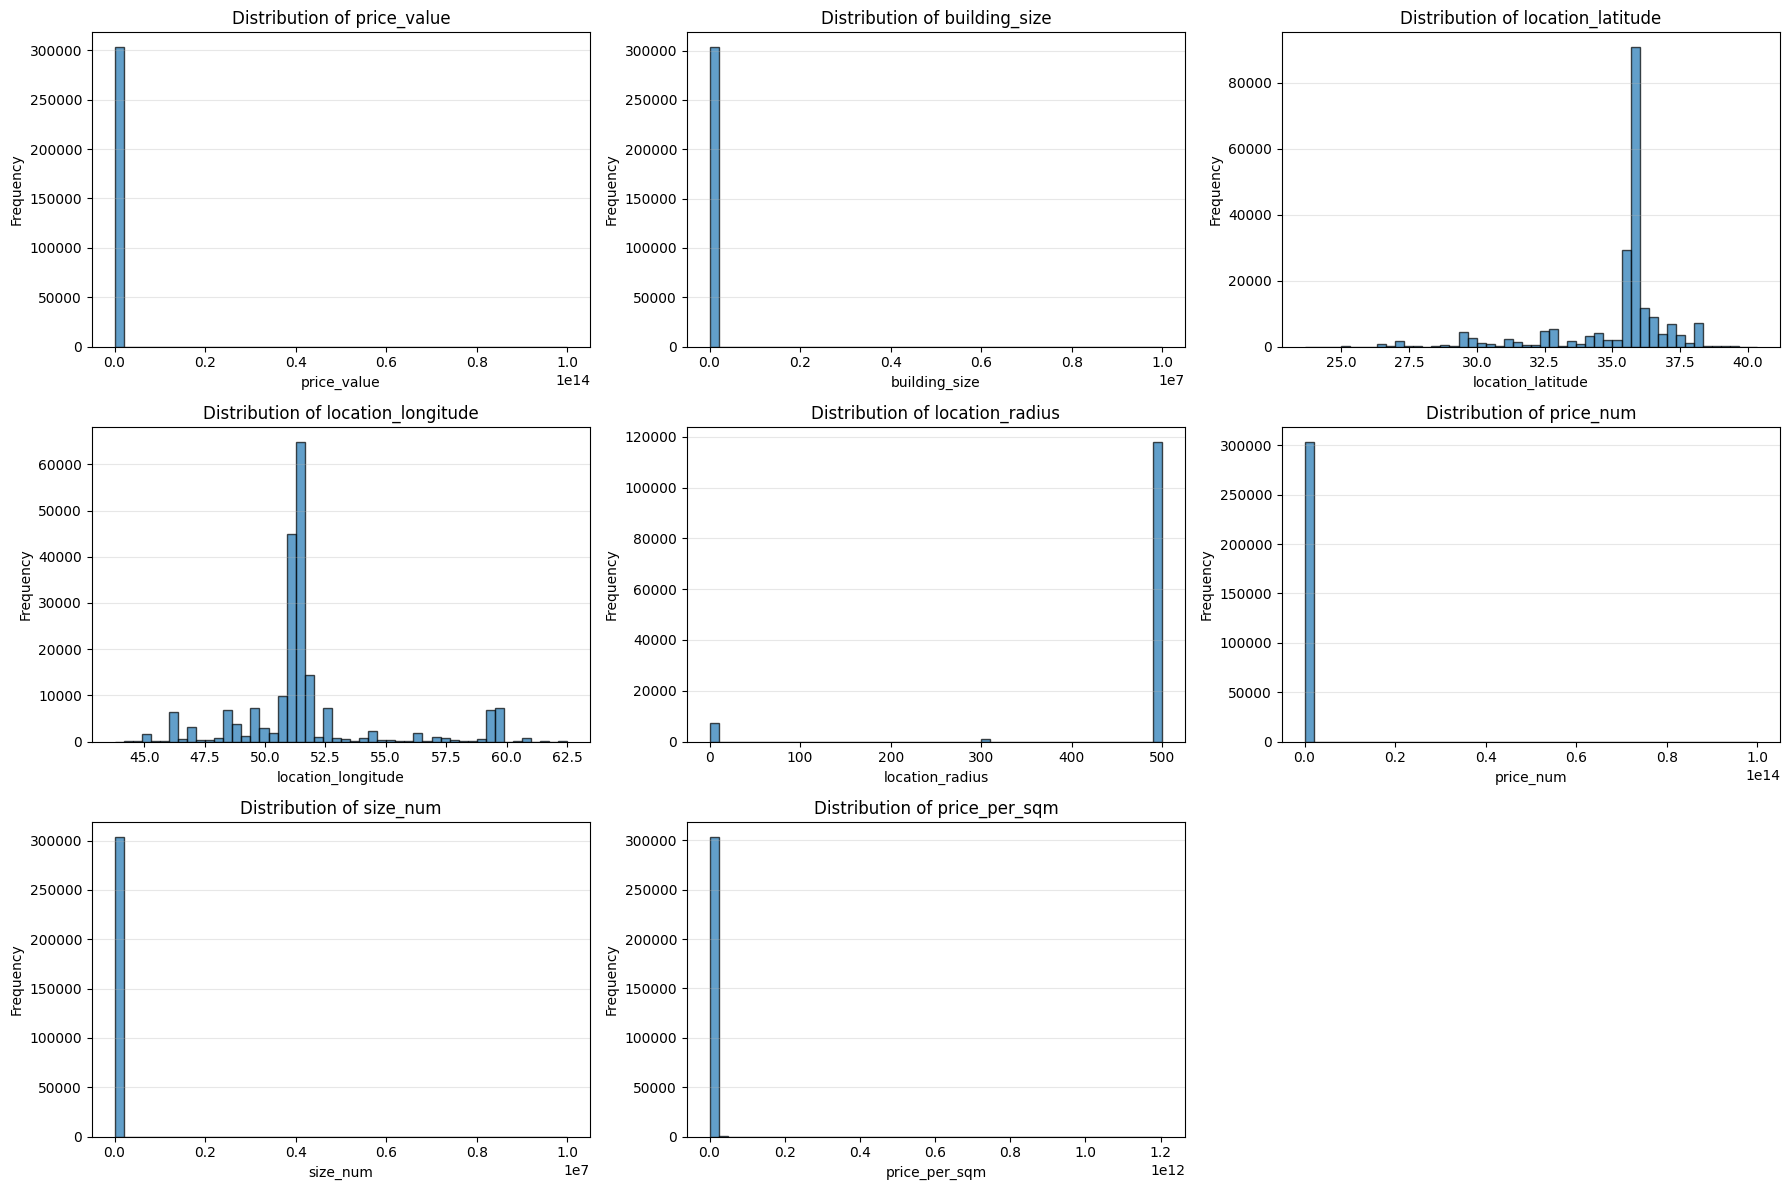

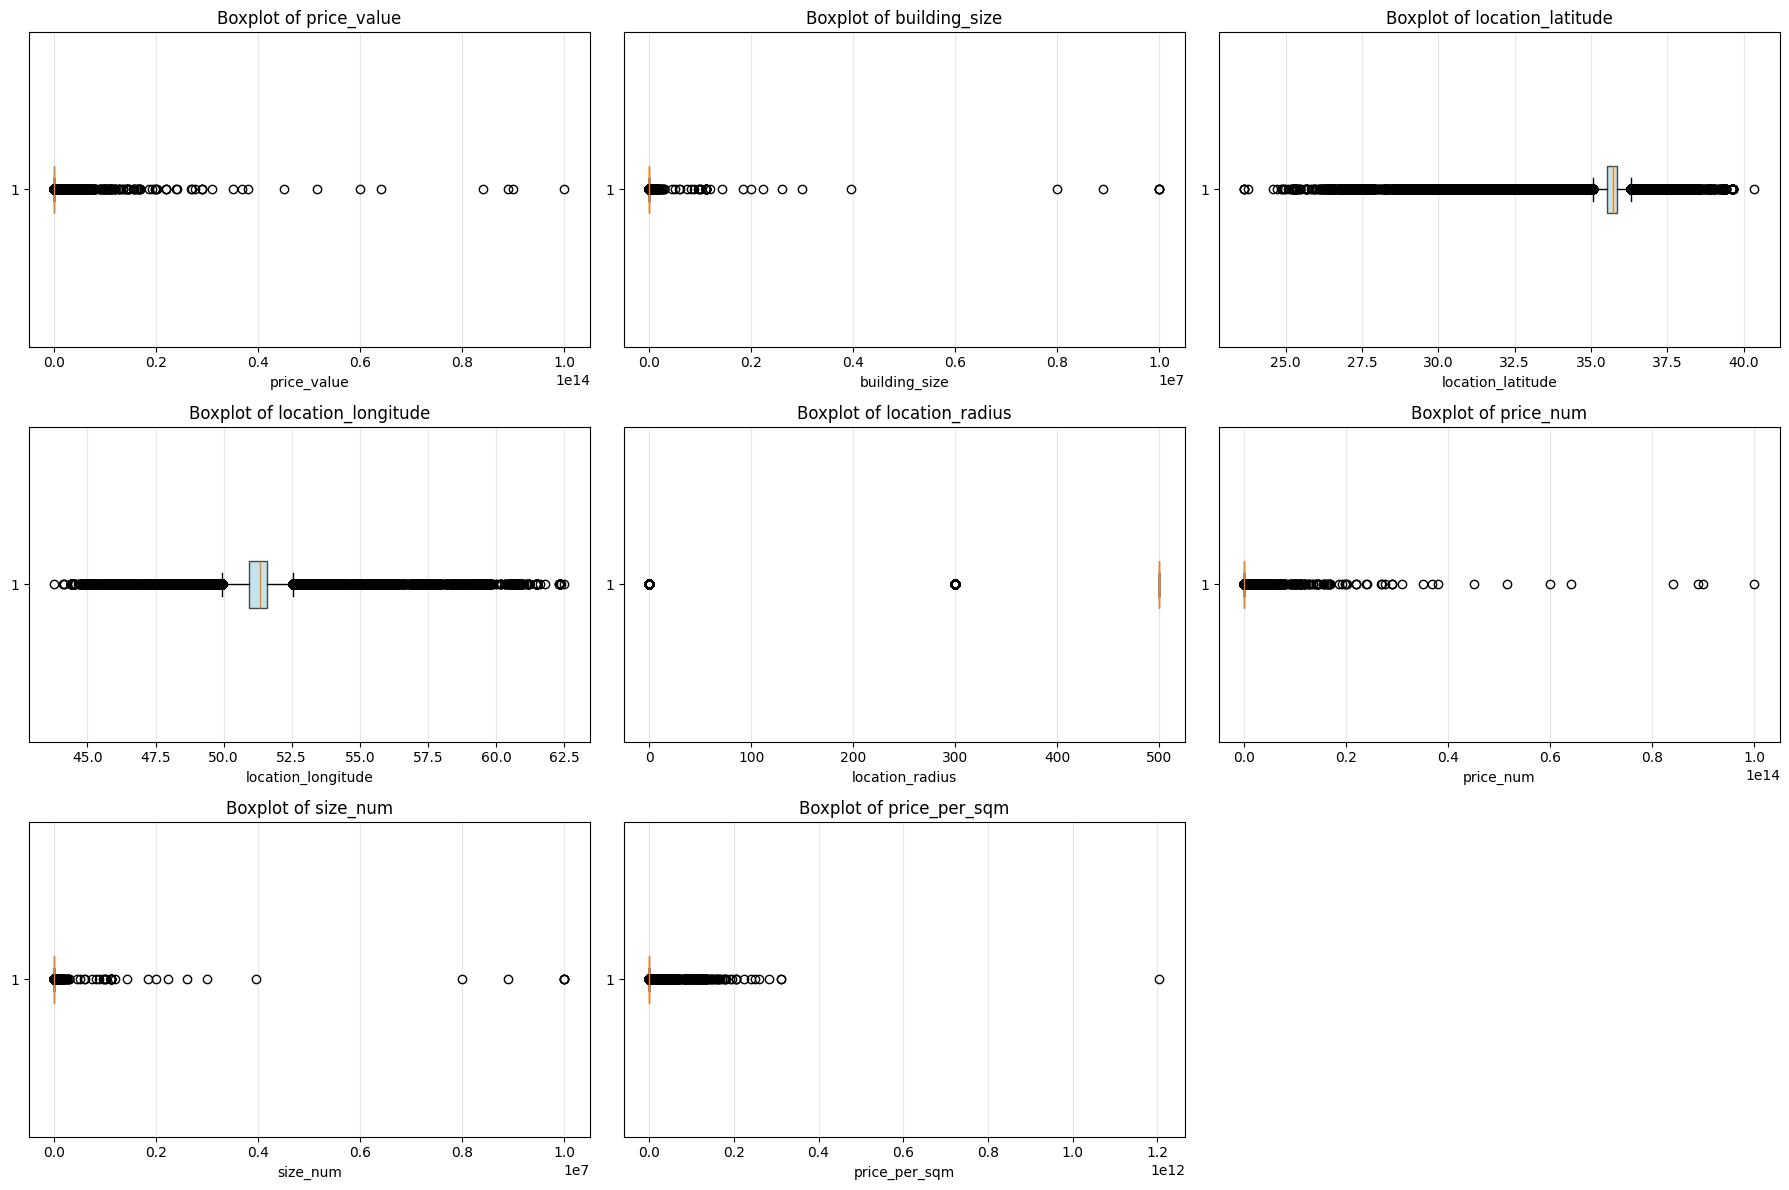

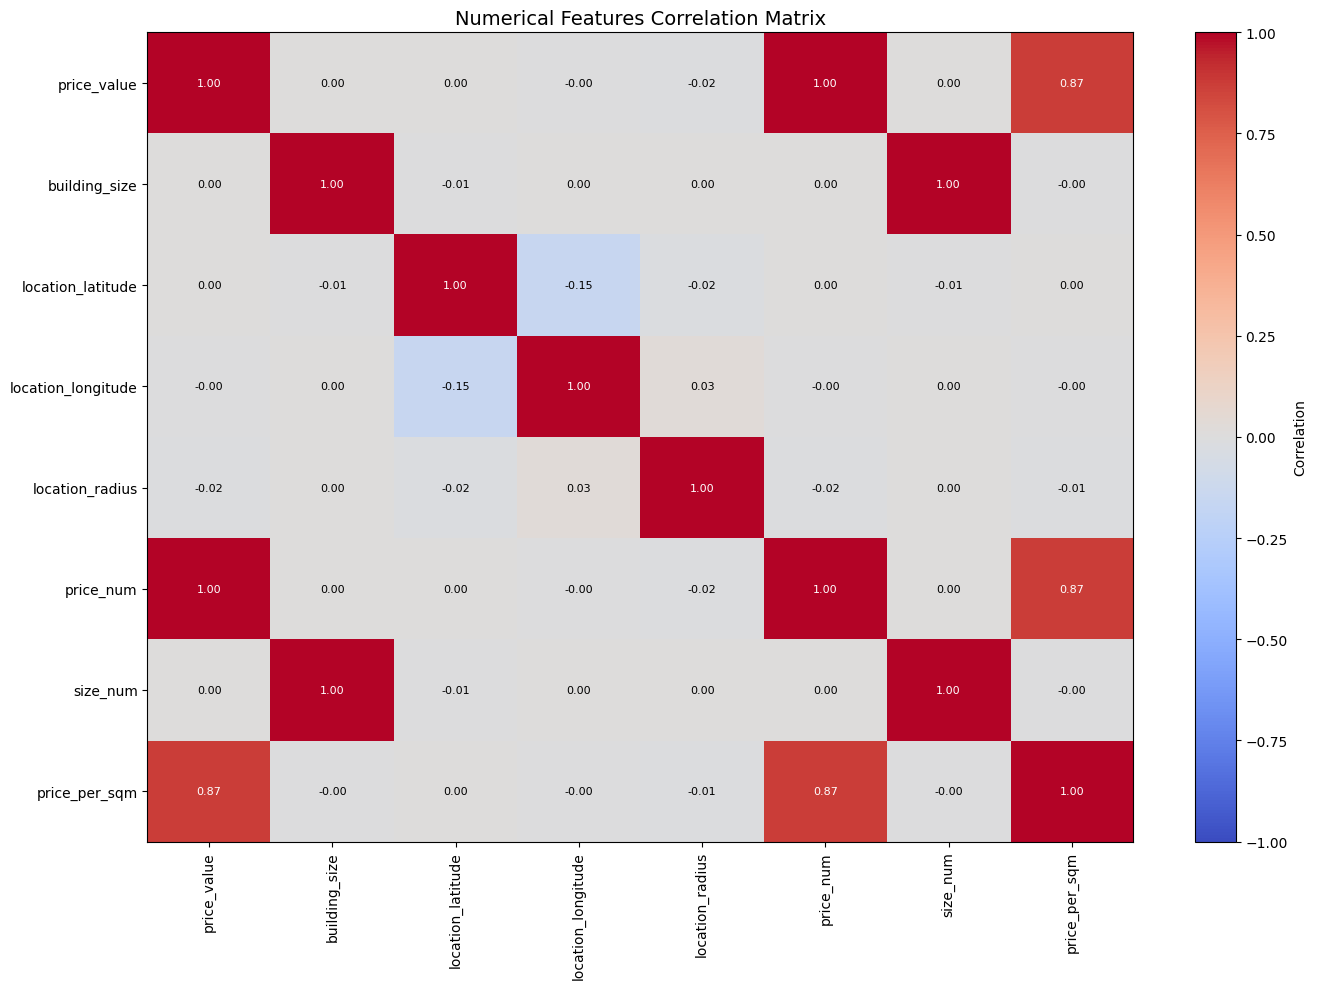

In [17]:
results = analyze_numerical_features(df_audit, verbose=False)

In [18]:
def setup_persian_font():
    plt.rcParams['font.family'] = 'DejaVu Sans'
    plt.rcParams['axes.unicode_minus'] = False

## 5. Categorical Features Analysis

In [19]:


# Set matplotlib font for Persian/Arabic support
def setup_persian_font():
    """Configure matplotlib to support Persian text rendering."""
    plt.rcParams['font.family'] = 'DejaVu Sans'
    plt.rcParams['axes.unicode_minus'] = False


def analyze_categorical_features(
    df: pd.DataFrame,
    figsize_per_plot: Tuple[int, int] = (10, 6),
    top_n_categories: int = 15,
    cardinality_threshold: int = 50,
    rare_threshold: int = 10,
    plots_per_row: int = 2,
    verbose: bool = True,
    persian_mode: bool = True
) -> Dict[str, Any]:
    """
    Comprehensive categorical features analysis for a DataFrame.
    Enhanced for Persian text support.

    Performs sections 6.1 through 6.8:
    - Identify categorical columns
    - Cardinality analysis
    - Top categories analysis
    - Category frequency distribution (bar plots)
    - High cardinality features
    - Rare categories analysis
    - Boolean-like features analysis
    - Key findings / answers to key questions

    Parameters
    ----------
    df : pd.DataFrame
        Input DataFrame to analyze.
    figsize_per_plot : tuple
        Base figure size for each subplot.
    top_n_categories : int
        Number of top categories to display in plots.
    cardinality_threshold : int
        Threshold for flagging high-cardinality features.
    rare_threshold : int
        Threshold for flagging rare categories (count < threshold).
    plots_per_row : int
        Number of plots per row in subplots.
    verbose : bool
        If True, prints detailed outputs.
    persian_mode : bool
        If True, applies Persian-specific formatting (RTL labels, font adjustments).

    Returns
    -------
    dict
        Dictionary containing all analysis results.
    """

    if persian_mode:
        setup_persian_font()

    results = {}

    # ========================================================================
    # 6.1. Identify Categorical Columns
    # ========================================================================
    categorical_cols = df.select_dtypes(
        include=["object", "category", "string"]
    ).columns.tolist()

    results["categorical_columns"] = categorical_cols

    if verbose:
        print("=" * 70)
        print("6.1. Identify Categorical Columns")
        print("=" * 70)
        print(f"Number of categorical columns: {len(categorical_cols)}")
        if categorical_cols:
            print("\nCategorical columns:")
            for col in categorical_cols:
                print(f"  - {col}")
        else:
            print("No categorical columns found.")

    if len(categorical_cols) == 0:
        if verbose:
            print("No categorical columns to analyze.")
        return results

    # ========================================================================
    # 6.2. Cardinality Analysis
    # ========================================================================
    categorical_summary = pd.DataFrame({
        "unique_values": df[categorical_cols].nunique(dropna=True),
        "missing_count": df[categorical_cols].isna().sum(),
        "missing_percentage": (df[categorical_cols].isna().mean() * 100)
    })
    categorical_summary = categorical_summary.sort_values(
        "unique_values", ascending=False
    )
    results["categorical_summary"] = categorical_summary

    if verbose:
        print("\n" + "=" * 70)
        print("6.2. Cardinality Analysis")
        print("=" * 70)
        print(categorical_summary.to_string())

    # ========================================================================
    # 6.3. Top Categories Analysis
    # ========================================================================
    top_categories_dict = {}
    if verbose:
        print("\n" + "=" * 70)
        print("6.3. Top Categories Analysis")
        print("=" * 70)

    for col in categorical_cols:
        top_cats = df[col].value_counts(dropna=False).head(10)
        top_categories_dict[col] = top_cats
        if verbose:
            print(f"\n{'=' * 60}")
            print(f"Feature: {col}")
            print(f"{'=' * 60}")
            print(top_cats.to_string())

    results["top_categories"] = top_categories_dict

    # ========================================================================
    # 6.4. Category Frequency Distribution (Bar Plots)
    # ========================================================================
    if len(categorical_cols) > 0:
        n_cols = plots_per_row
        n_rows = math.ceil(len(categorical_cols) / n_cols)

        fig, axes = plt.subplots(
            n_rows, n_cols,
            figsize=(figsize_per_plot[0] * n_cols, figsize_per_plot[1] * n_rows)
        )
        if n_rows == 1 and n_cols == 1:
            axes = [axes]
        else:
            axes = axes.flatten()

        for i, col in enumerate(categorical_cols):
            top_categories = (
                df[col]
                .value_counts(dropna=False)
                .head(top_n_categories)
            )

            # Convert index to string to handle mixed types (NaN, numbers, etc.)
            plot_data = top_categories.copy()
            plot_data.index = plot_data.index.astype(str)

            ax = axes[i]
            bars = ax.bar(
                range(len(plot_data)),
                plot_data.values,
                color='steelblue',
                edgecolor='black',
                alpha=0.8
            )

            # Persian-friendly label formatting
            labels = plot_data.index.tolist()
            ax.set_xticks(range(len(labels)))

            if persian_mode:
                # For Persian/RTL text: rotate more, align right, smaller font
                ax.set_xticklabels(
                    labels,
                    rotation=60,
                    ha='right',
                    fontsize=9,
                    fontfamily='DejaVu Sans'
                )
                # Adjust title and axis labels for Persian
                ax.set_title(
                    f"Top {top_n_categories} Categories — {col}",
                    fontsize=12,
                    fontfamily='DejaVu Sans'
                )
                ax.set_xlabel(col, fontsize=10, fontfamily='DejaVu Sans')
                ax.set_ylabel("Frequency", fontsize=10, fontfamily='DejaVu Sans')
            else:
                ax.set_xticklabels(labels, rotation=75, ha='right', fontsize=9)
                ax.set_title(f"Top {top_n_categories} Categories — {col}", fontsize=12)
                ax.set_xlabel(col)
                ax.set_ylabel("Frequency")

            ax.grid(axis='y', alpha=0.3)

            # Add value labels on top of bars for better readability
            for bar in bars:
                height = bar.get_height()
                ax.annotate(
                    f'{int(height)}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom',
                    fontsize=7,
                    fontfamily='DejaVu Sans' if persian_mode else None
                )

        for j in range(i + 1, len(axes)):
            axes[j].set_visible(False)

        plt.tight_layout()
        plt.savefig(
            "categorical_frequency_plots.png",
            dpi=150,
            bbox_inches="tight",
            facecolor='white'
        )
        plt.show()
        results["frequency_figure"] = fig

    if verbose:
        print("\n" + "=" * 70)
        print("6.4. Category Frequency Distribution")
        print("=" * 70)
        print(f"Bar plots generated for top {top_n_categories} categories per feature.")

    # ========================================================================
    # 6.5. High Cardinality Features
    # ========================================================================
    high_cardinality_cols = (
        categorical_summary[
            categorical_summary["unique_values"] > cardinality_threshold
        ].index.tolist()
    )
    results["high_cardinality_features"] = high_cardinality_cols

    if verbose:
        print("\n" + "=" * 70)
        print("6.5. High Cardinality Features")
        print("=" * 70)
        print(f"Threshold: {cardinality_threshold} unique values")
        if high_cardinality_cols:
            print("\nHigh-cardinality features:")
            for col in high_cardinality_cols:
                unique_count = categorical_summary.loc[col, 'unique_values']
                print(f"  - {col}: {unique_count:,} unique values")
        else:
            print("No high-cardinality features found.")

    # ========================================================================
    # 6.6. Rare Categories Analysis
    # ========================================================================
    rare_category_results = []
    for col in categorical_cols:
        counts = df[col].value_counts(dropna=True)
        rare_categories = counts[counts < rare_threshold]
        rare_category_results.append({
            "feature": col,
            "total_categories": len(counts),
            "rare_categories_count": len(rare_categories),
            "rare_records_count": rare_categories.sum(),
            "rare_records_percentage": (
                rare_categories.sum() / len(df) * 100
            ) if len(df) > 0 else 0
        })

    rare_category_summary = pd.DataFrame(
        rare_category_results
    ).sort_values("rare_records_count", ascending=False)
    results["rare_category_summary"] = rare_category_summary

    if verbose:
        print("\n" + "=" * 70)
        print("6.6. Rare Categories Analysis")
        print("=" * 70)
        print(f"Rare threshold: < {rare_threshold} occurrences")
        print(rare_category_summary.to_string(index=False))

    # ========================================================================
    # 6.7. Boolean-like Categorical Features
    # ========================================================================
    boolean_like_cols = [
        col for col in categorical_cols
        if df[col].dropna().nunique() <= 2
    ]
    results["boolean_like_features"] = boolean_like_cols

    boolean_distributions = {}
    if verbose:
        print("\n" + "=" * 70)
        print("6.7. Boolean-like Categorical Features")
        print("=" * 70)
        print(f"Boolean-like features (<= 2 unique values): {len(boolean_like_cols)}")
        if boolean_like_cols:
            print("\nFeatures:")
            for col in boolean_like_cols:
                print(f"  - {col}")
            print("\nFrequency distributions:")
            for col in boolean_like_cols:
                dist = df[col].value_counts(dropna=False)
                boolean_distributions[col] = dist
                print(f"\n  {col}:")
                print(f"  {dist.to_string()}")
        else:
            print("No boolean-like categorical features found.")
    else:
        for col in boolean_like_cols:
            boolean_distributions[col] = df[col].value_counts(dropna=False)

    results["boolean_distributions"] = boolean_distributions

    # ========================================================================
    # 6.8. Key Findings
    # ========================================================================
    if verbose:
        print("\n" + "=" * 70)
        print("6.8. Categorical Features Analysis — Key Findings")
        print("=" * 70)

    findings = {}

    # Q1: Features with highest cardinality
    highest_cardinality = categorical_summary.sort_values(
        "unique_values", ascending=False
    ).head(5)
    findings["highest_cardinality"] = highest_cardinality
    if verbose:
        print("\n1. Features with highest cardinality (most unique categories):")
        print(highest_cardinality.to_string())

    # Q2: Features with lowest cardinality
    lowest_cardinality = categorical_summary.sort_values(
        "unique_values", ascending=True
    ).head(5)
    findings["lowest_cardinality"] = lowest_cardinality
    if verbose:
        print("\n2. Features with lowest cardinality (fewest unique categories):")
        print(lowest_cardinality.to_string())

    # Q3: Most frequent categories per feature
    most_frequent = {}
    for col in categorical_cols:
        most_frequent[col] = df[col].value_counts(dropna=False).iloc[0]
    most_frequent_df = pd.DataFrame({
        "feature": list(most_frequent.keys()),
        "most_frequent_count": list(most_frequent.values())
    }).sort_values("most_frequent_count", ascending=False)
    findings["most_frequent_categories"] = most_frequent_df
    if verbose:
        print("\n3. Most frequent category count per feature:")
        print(most_frequent_df.head(10).to_string(index=False))

    # Q4: Rare categories summary
    features_with_rare = rare_category_summary[
        rare_category_summary["rare_categories_count"] > 0
    ].sort_values("rare_records_count", ascending=False)
    findings["features_with_rare"] = features_with_rare
    if verbose:
        print("\n4. Features with rare categories:")
        if len(features_with_rare) > 0:
            print(features_with_rare.to_string(index=False))
        else:
            print("   No rare categories found.")

    # Q5: Features with most missing values
    missing_top = categorical_summary[
        categorical_summary["missing_count"] > 0
    ].sort_values("missing_percentage", ascending=False)
    findings["most_missing"] = missing_top
    if verbose:
        print("\n5. Features with most missing values:")
        if len(missing_top) > 0:
            print(missing_top.head(5).to_string())
        else:
            print("   No missing values in categorical features.")

    # Q6: Boolean-like feature balance check
    if verbose:
        print("\n6. Boolean-like feature balance check:")
        if boolean_like_cols:
            for col in boolean_like_cols:
                dist = df[col].value_counts(dropna=False, normalize=True) * 100
                print(f"   {col}:")
                for val, pct in dist.items():
                    print(f"     {val}: {pct:.1f}%")
        else:
            print("   No boolean-like features to check.")

    # Q7: Very high cardinality features (> 1000)
    very_high_cardinality = categorical_summary[
        categorical_summary["unique_values"] > 1000
    ]
    findings["very_high_cardinality"] = very_high_cardinality
    if verbose:
        print("\n7. Very high cardinality features (> 1000 unique values):")
        if len(very_high_cardinality) > 0:
            print(very_high_cardinality.to_string())
        else:
            print("   None found.")

    # Q8: Check for inconsistent formatting
    inconsistent_features = []
    for col in categorical_cols:
        values = df[col].dropna().astype(str)
        has_leading_space = values.str.startswith(' ').any()
        has_trailing_space = values.str.endswith(' ').any()
        has_mixed_case = (
            values.str.islower().any() and values.str.isupper().any()
        )
        if has_leading_space or has_trailing_space or has_mixed_case:
            inconsistent_features.append({
                "feature": col,
                "leading_spaces": has_leading_space,
                "trailing_spaces": has_trailing_space,
                "mixed_case": has_mixed_case
            })

    inconsistent_df = pd.DataFrame(inconsistent_features)
    findings["inconsistent_formatting"] = inconsistent_df
    if verbose:
        print("\n8. Inconsistent formatting issues:")
        if len(inconsistent_df) > 0:
            print(inconsistent_df.to_string(index=False))
        else:
            print("   No inconsistent formatting detected.")

    results["findings"] = findings

    if verbose:
        print("\n" + "=" * 70)
        print("Analysis complete.")
        print("=" * 70)

    return results


6.1. Identify Categorical Columns
Number of categorical columns: 43

Categorical columns:
  - cat2_slug
  - cat3_slug
  - city_slug
  - neighborhood_slug
  - created_at_month
  - user_type
  - description
  - title
  - rent_mode
  - rent_to_single
  - rent_type
  - price_mode
  - credit_mode
  - rent_credit_transform
  - transformable_price
  - deed_type
  - has_business_deed
  - floor
  - rooms_count
  - total_floors_count
  - unit_per_floor
  - has_balcony
  - has_elevator
  - has_warehouse
  - has_parking
  - construction_year
  - is_rebuilt
  - has_water
  - has_warm_water_provider
  - has_electricity
  - has_gas
  - has_heating_system
  - has_cooling_system
  - has_restroom
  - has_security_guard
  - has_barbecue
  - building_direction
  - has_pool
  - has_jacuzzi
  - has_sauna
  - floor_material
  - property_type
  - extra_person_capacity

6.2. Cardinality Analysis
                         unique_values  missing_count  missing_percentage
description                     989449    

/tmp/ipykernel_16/573564309.py:208: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_16/573564309.py:208: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_16/573564309.py:208: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()
/tmp/ipykernel_16/573564309.py:209: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(
/tmp/ipykernel_16/573564309.py:209: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.savefig(
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: 




6.4. Category Frequency Distribution
Bar plots generated for top 15 categories per feature.

6.5. High Cardinality Features
Threshold: 50 unique values

High-cardinality features:
  - description: 989,449 unique values
  - title: 904,092 unique values
  - neighborhood_slug: 1,188 unique values
  - city_slug: 421 unique values

6.6. Rare Categories Analysis
Rare threshold: < 10 occurrences
                feature  total_categories  rare_categories_count  rare_records_count  rare_records_percentage
            description            989449                 989356              997733                  99.7733
                  title            904092                 902632              946581                  94.6581
      neighborhood_slug              1188                    109                 323                   0.0323
       created_at_month                46                     19                  67                   0.0067
              city_slug               421                

{'categorical_columns': ['cat2_slug',
  'cat3_slug',
  'city_slug',
  'neighborhood_slug',
  'created_at_month',
  'user_type',
  'description',
  'title',
  'rent_mode',
  'rent_to_single',
  'rent_type',
  'price_mode',
  'credit_mode',
  'rent_credit_transform',
  'transformable_price',
  'deed_type',
  'has_business_deed',
  'floor',
  'rooms_count',
  'total_floors_count',
  'unit_per_floor',
  'has_balcony',
  'has_elevator',
  'has_warehouse',
  'has_parking',
  'construction_year',
  'is_rebuilt',
  'has_water',
  'has_warm_water_provider',
  'has_electricity',
  'has_gas',
  'has_heating_system',
  'has_cooling_system',
  'has_restroom',
  'has_security_guard',
  'has_barbecue',
  'building_direction',
  'has_pool',
  'has_jacuzzi',
  'has_sauna',
  'floor_material',
  'property_type',
  'extra_person_capacity'],
 'categorical_summary':                          unique_values  missing_count  missing_percentage
 description                     989449              0              

In [20]:
analyze_categorical_features(df, persian_mode=True)

# Data Understanding — Key Findings

---

## 1. Dataset Overview — Key Findings

The selected apartment sales dataset contains 303,385 records and 60 columns.

The main findings are:

1. **Dataset Scope**
   - The analysis is restricted to residential apartment sale advertisements.
   - All records belong to `residential-sell` and `apartment-sell`.

2. **Dataset Structure**
   - The dataset contains numerical, categorical, geographical, temporal, and text-based features.
   - Several columns contain property characteristics, amenities, listing information, and price-related information.

3. **Target Variable**
   - `price_value` is the primary candidate target variable.
   - It represents the asking price reported in advertisements, not necessarily the final transaction price.

**Conclusion:**

The selected dataset provides a substantial collection of residential apartment sale advertisements with diverse property, price, and location information.

---

## 2. Numerical Features Analysis — Key Findings

The numerical analysis revealed considerable variation in the distributions of property prices and structural characteristics.

The main findings are:

1. **Price Distribution**
   - `price_value` has a median of approximately 3.3 billion.
   - The mean is considerably higher than the median.
   - The 99th percentile is approximately 55 billion, while the maximum reaches 100 trillion.
   - The distribution contains extreme upper-end values.

2. **Missing Values**
   - `price_value` contains 5 missing values.
   - `building_size` contains 5 missing values.
   - `land_size` is completely missing in the selected dataset.

3. **Building Size**
   - The median `building_size` is 90.
   - The 99th percentile is approximately 290.
   - The maximum value is 10,000,000, which is substantially higher than the typical observed values.

4. **Structural Features**
   - `total_floors_count` has approximately 38.34% missing values.
   - `unit_per_floor` has approximately 39.05% missing values.
   - `rooms_count` contains categorical room-count values rather than a consistently numerical representation.

5. **Data Distribution**
   - Both price and building size contain extreme values.
   - The difference between central statistics and maximum values indicates highly dispersed distributions.

**Conclusion:**

The numerical features exhibit different distributions and levels of completeness. Price and building size contain extreme observed values, while some structural features have substantial missing data.

---

## 3. Target Variable Analysis — Key Findings

The analysis of `price_value` and `price_mode` revealed different price-reporting conditions in the advertisements.

The main findings are:

1. **Price Mode Distribution**
   - `مقطوع` is the dominant category, with 302,642 records.
   - `مجانی` appears in 738 records.
   - `توافقی` appears in 3 records.
   - Two records have missing `price_mode` values.

2. **Missing Target Values**
   - `price_value` contains 5 missing values.
   - The minimum observed price is zero.

3. **Descriptive Statistics**
   - Median: approximately 3.3 billion.
   - Mean: approximately 15.50 billion.
   - 95th percentile: approximately 19.5 billion.
   - 99th percentile: approximately 55 billion.
   - Maximum: 100 trillion.

4. **Distribution Characteristics**
   - The mean is substantially higher than the median.
   - The standard deviation is very large.
   - The upper tail contains values considerably higher than the central distribution.

5. **Interpretation**
   - The target represents advertised asking prices.
   - The observed distribution alone does not establish whether extreme prices are valid or invalid.
   - The currency unit cannot be confirmed from the analyzed statistics alone.

**Conclusion:**

The target variable has a highly dispersed distribution with a dominant fixed-price category and a small number of alternative price-reporting conditions. Its statistical characteristics should be documented carefully.

---

## 4. Geographic Features Analysis — Key Findings

The geographic analysis examined five columns related to city, neighborhood, and listing coordinates.

The main findings are:

1. **Geographic Coverage**
   - `city_slug` contains 383 unique cities with no missing values.
   - `neighborhood_slug` contains 1,119 unique values.
   - Approximately 44.64% of neighborhood values are missing.

2. **City Distribution**
   - Tehran has the highest number of advertisements, with 84,586 records.
   - Mashhad follows with 24,331 records.
   - Karaj contains 20,870 records.
   - The dataset has an uneven distribution of advertisements across cities.

3. **Neighborhood Coverage**
   - Neighborhood information is not equally available across cities.
   - Some cities have complete neighborhood information.
   - Other cities have no recorded neighborhood values in the selected subset.

4. **Coordinate Availability**
   - 205,072 records contain both latitude and longitude.
   - Approximately 67.59% of records have complete coordinate pairs.
   - The remaining records have incomplete coordinate information.

5. **Coordinate Range**
   - Seven coordinate pairs fall outside the approximate geographic bounding box used for Iran.
   - The remaining coordinate pairs fall within the selected bounds.
   - This range check does not independently verify the actual property locations.

6. **Location Radius**
   - `location_radius` contains three distinct non-null values: 0, 300, and 500.
   - Approximately 58.48% of its values are missing.
   - Its exact meaning is not established by the available analysis.

**Conclusion:**

The dataset provides complete city-level information but has substantial missingness in neighborhood and coordinate fields. Geographic coverage also varies across cities.

---

## 5. Categorical Features Analysis — Key Findings

The categorical analysis identified 43 categorical columns in the apartment sales dataset.

The main findings are:

1. **High Cardinality Features**
   - `description` and `title` contain a very large number of unique values because they represent free-text content.
   - `neighborhood_slug` contains 1,119 unique values, with approximately 44.64% missing data.
   - `city_slug` contains 383 unique cities with no missing values.

2. **Completely Missing Features**
   - Nine categorical columns contain no non-null values in this dataset.
   - These columns are related mainly to rental, credit, or other property information.

3. **Constant Features**
   - `cat2_slug` and `cat3_slug` have only one unique value because the dataset is restricted to residential apartment sales.
   - Several property-related features also contain only one observed value and are almost entirely missing.

4. **Important Categorical Features**
   - `price_mode` is dominated by the `مقطوع` category.
   - `user_type` has approximately 63.5% missing values.
   - `has_elevator`, `has_warehouse`, and `has_parking` have relatively high data coverage.
   - Other property-related features contain multiple categories and varying levels of missing data.

5. **Rare Categories**
   - Rare values exist in geographical and structural features.
   - Rare-category statistics for `title` and `description` are not directly meaningful because these columns contain free text.

6. **Data Representation Observations**
   - Some Boolean-like values have inconsistent capitalization, such as `true` and `True`.
   - Some categorical columns contain special values such as `unselect`.
   - These observations indicate differences in data representation.

7. **Text Features**
   - `title` and `description` require separate text analysis because of their high cardinality and free-text nature.

**Conclusion:**

The dataset contains a mixture of geographical, structural, temporal, Boolean-like, and free-text categorical features. Their cardinality and missing-value patterns vary considerably. These findings provide an overview of categorical data characteristics without applying any cleaning or transformation.

---

## 6. Text Features Analysis — Key Findings

The text analysis identified `title` and `description` as the two main free-text columns.

The main findings are:

1. **High Cardinality**
   - `description` contains 300,219 unique values.
   - `title` contains 289,156 unique values.
   - Both columns have extremely high cardinality compared with ordinary categorical features.

2. **Missing Values**
   - `description` has no missing values.
   - `title` contains 13 missing values.

3. **Text Content**
   - Descriptions contain information about property characteristics and building amenities.
   - Some descriptions include payment conditions, sales messages, and promotional language.
   - Contact information, addresses, emojis, and formatting symbols are also present.

4. **Unstructured Information**
   - The text fields contain a mixture of property-related information and non-structural content.
   - Their content is not limited to standardized property descriptions.

5. **Analysis Scope**
   - The current analysis focuses on the structure, cardinality, and completeness of text fields.
   - No NLP processing or information extraction has been performed.

**Conclusion:**

The title and description columns contain extensive unstructured Persian text with very high cardinality. Their characteristics differ substantially from conventional categorical features.

---

## 7. Temporal Features Analysis — Key Findings

The temporal analysis examined the `created_at_month` column.

The main findings are:

1. **Temporal Coverage**
   - `created_at_month` contains 36 unique monthly values.
   - No missing values were observed.

2. **Monthly Distribution**
   - December 2024 contains 41,340 advertisements.
   - November 2024 contains 41,102 advertisements.
   - October 2024 contains 39,603 advertisements.
   - July and August 2024 also have relatively high advertisement counts.

3. **Uneven Distribution**
   - The number of advertisements varies considerably across months.
   - The monthly distribution is not uniform.

4. **Time Representation**
   - The feature is represented as a monthly categorical value.
   - It provides information about the month in which advertisements were created.

**Conclusion:**

The dataset contains complete monthly information for the analyzed records, although advertisement counts vary across the observed months.

---

## 8. Overall Data Understanding — Key Findings

The Data Understanding phase examined the structure, distributions, completeness, and observable characteristics of the selected apartment sales dataset.

The main findings are:

1. **Dataset Structure**
   - The selected dataset contains 303,385 records and 60 columns.
   - It includes numerical, categorical, geographical, temporal, and text-based information.

2. **Target Variable**
   - `price_value` represents the advertised asking price.
   - Its distribution is highly dispersed and contains extreme upper-end values.

3. **Numerical Features**
   - `building_size` contains extreme observed values.
   - `land_size` is completely missing.
   - Some structural features have substantial missingness.

4. **Geographic Features**
   - City information is complete.
   - Neighborhood information is missing in approximately 44.64% of records.
   - Complete coordinate pairs are available for approximately 67.59% of records.

5. **Categorical Features**
   - Several categorical columns are completely missing.
   - Some columns are constant due to the selected dataset scope.
   - Boolean-like values show occasional inconsistencies in representation.

6. **Text Features**
   - `title` and `description` contain high-cardinality free text.
   - Their content includes both property-related and promotional information.

7. **Temporal Features**
   - `created_at_month` has no missing values.
   - Advertisement counts vary across months.

8. **Data Quality Observations**
   - The dataset contains missing values, extreme observations, high-cardinality fields, and inconsistent representations.
   - These observations describe the current data and do not imply that any modifications have been applied.

**Conclusion:**

The Data Understanding phase provides a comprehensive overview of the selected apartment sales dataset, including its structure, target distribution, numerical characteristics, geographical coverage, categorical features, text content, and temporal information. No data cleaning, transformation, feature engineering, or modeling has been performed during this phase.
